# TCG ML Primer: Predicting Hotel Booking Cancellations

This notebook works through the full TCG DSML Primer process on a new dataset. It follows the same steps as the coffee-sales example:

1. Problem definition
2. Load data & missing values
3. Exploratory Data Analysis (EDA)
4. Data cleaning
5. Feature engineering & feature selection
6. Train / test split
7. Preprocessing pipeline, baseline & model selection
8. Evaluation & cross-validation
9. Hyperparameter tuning
10. Interpretation & error analysis
11. Business recommendations

# STEP 0: Imports

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    ExtraTreesClassifier
)

from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    roc_auc_score, f1_score, precision_score, recall_score
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

## STEP 1: Question

**Dataset:** [Hotel Booking Demand](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand) (Antonio, Almeida & Nunes, 2019). It contains about 119k real bookings from two hotels in Portugal, a **City Hotel** and a **Resort Hotel**, with arrival dates from July 2015 to August 2017.

**The business problem:** Cancellations cost hotels money. A cancelled room that goes unsold earns nothing. To protect themselves, hotels *overbook*, but if they overbook too much and everyone shows up, they have to "walk" guests to another hotel, which is expensive and bad for their reputation. If the hotel knew **at booking time** which reservations were likely to cancel, it could:
- overbook more precisely,
- ask high-risk bookings for a deposit or confirmation,
- target high-risk guests with retention offers.

**Data science question:** *Using only information available when a booking is made, can we predict whether that booking will be cancelled?*

- **Task type:** supervised, **binary classification**
- **Target:** `is_canceled` (1 = cancelled, 0 = not cancelled)
- **Metrics:** The primer used accuracy. About 37% of bookings cancel, so accuracy alone can hide a model that is weak on cancellations. We will report:
  - **ROC-AUC** (main metric for comparing models): how well the model *ranks* risky bookings above safe ones. It doesn't depend on a decision threshold. 0.5 = random guessing, 1.0 = perfect.
  - **Accuracy, precision, recall, F1** for the cancelled class, so we can explain results in business terms. For example, recall answers "of the bookings that actually cancelled, how many did we catch?"

**Columns that could help (brainstorm):** lead time (how far ahead the booking was made), deposit type, previous cancellations, market segment and distribution channel (online travel agent vs. direct), customer type, special requests, parking requests, price (ADR), length of stay, arrival season, and country.

## STEP 2: Loading the Dataset

In [2]:
df = pd.read_csv("data/hotel_bookings.csv")  # relative path: works for anyone who clones the repo
print("Shape:", df.shape)
df.head()

Shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


Unlike the coffee notebook, we **don't need to inject fake nulls**. This dataset already has real missing values, which we'll find below.

## STEP 3: EDA

First, a general look at the dataset:
- What columns are there?
- What does each column tell us?
- Which columns relate to our question?
- Are any columns unnecessary, or even *dangerous* to use?

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


### Column guide

| Column | Meaning | Known at booking time? |
|---|---|---|
| `hotel` | City Hotel or Resort Hotel | ✅ |
| `is_canceled` | **TARGET**: 1 if the booking was cancelled | — |
| `lead_time` | Days between booking and arrival | ✅ |
| `arrival_date_year / month / week_number / day_of_month` | Arrival date | ✅ |
| `stays_in_weekend_nights`, `stays_in_week_nights` | Length of stay | ✅ |
| `adults`, `children`, `babies` | Party size | ✅ |
| `meal` | Meal package (BB = bed & breakfast, HB = half board, FB = full board, SC/Undefined = none) | ✅ |
| `country` | Guest's country of origin | ✅ (mostly) |
| `market_segment`, `distribution_channel` | How the booking came in (Online TA, Groups, Direct, …) | ✅ |
| `is_repeated_guest`, `previous_cancellations`, `previous_bookings_not_canceled` | Guest history | ✅ |
| `reserved_room_type` | Room type booked | ✅ |
| `assigned_room_type` | Room type actually given | ❌ decided at check-in |
| `booking_changes` | Number of changes before check-in/cancellation | ❌ builds up over time |
| `deposit_type` | No Deposit / Non Refund / Refundable | ✅ |
| `agent`, `company` | ID of the travel agent or company that booked | ✅ |
| `days_in_waiting_list` | Days before the booking was confirmed | ⚠️ known shortly after booking |
| `customer_type` | Transient, Contract, Group, Transient-Party | ✅ |
| `adr` | Average Daily Rate (price per night) | ✅ |
| `required_car_parking_spaces`, `total_of_special_requests` | Extra requests | ✅ (mostly) |
| `reservation_status` | Canceled / Check-Out / No-Show | ❌ **this IS the outcome** |
| `reservation_status_date` | Date of the last status change | ❌ after the fact |

**Which columns are relevant to our question?**

Answer: Anything we would actually know **when the booking is made**. Lead time, deposit type, market segment, distribution channel, customer type, guest history (previous cancellations, repeated guest), special/parking requests, ADR, stay length, party size, arrival month/week, hotel type, and country all look relevant.

Some columns are **unnecessary or dangerous**:
- `reservation_status` gives away the target (see the check below). Keeping it would give a "perfect" model that's useless in practice, because when you're making the prediction you don't know the status yet. This is called **target leakage**.
- `reservation_status_date`, `assigned_room_type`, and `booking_changes` are only known *after* the booking plays out, so they leak information from the future.
- `company` is about 94% missing, and `agent`/`company` are ID numbers with hundreds of values (we'll simplify them in feature engineering rather than use the raw IDs).

In [5]:
# proof that reservation_status leaks the target: it maps 1-to-1 onto is_canceled
pd.crosstab(df["reservation_status"], df["is_canceled"])

is_canceled,0,1
reservation_status,,
Canceled,0,43017
Check-Out,75166,0
No-Show,0,1207


### Let's explore a little more

1. How balanced is the target?
2. Which values are missing, and where?
3. Which features seem to separate cancellations from non-cancellations?

In [6]:
print(df["is_canceled"].value_counts())
print()
print(df["is_canceled"].value_counts(normalize=True).round(3))

is_canceled
0    75166
1    44224
Name: count, dtype: int64

is_canceled
0    0.63
1    0.37
Name: proportion, dtype: float64


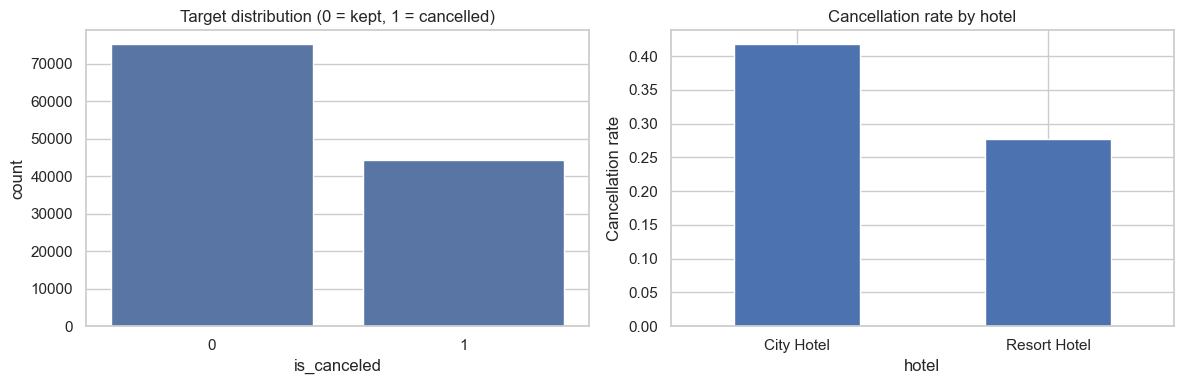

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="is_canceled", ax=axes[0])
axes[0].set_title("Target distribution (0 = kept, 1 = cancelled)")
axes[0].set_xlabel("is_canceled")

df.groupby("hotel")["is_canceled"].mean().plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("Cancellation rate by hotel")
axes[1].set_ylabel("Cancellation rate")
plt.tight_layout()
plt.show()

**Class balance:** About 63% of bookings are kept and 37% cancelled. That's imbalanced but not extreme. A "lazy" model that always predicts *not cancelled* would already get ~63% accuracy, so **63% is the bar to beat**, not 50%. The City Hotel cancels much more often (~42%) than the Resort Hotel (~28%).

### Missing Values

In [8]:
missing_summary = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percent": (df.isnull().mean() * 100).round(2)
})
missing_summary[missing_summary["missing_count"] > 0].sort_values("missing_count", ascending=False)

,missing_count,missing_percent
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


Note: in the raw CSV, missing `agent`/`company` values are written as the text `"NULL"`, and pandas converts them to `NaN` automatically.

| Column | % missing | What the missing value *means* | Plan |
|---|---|---|---|
| `company` | ~94% | No company was involved in the booking | Turn into a yes/no flag `has_company` |
| `agent` | ~14% | Booked without a travel agent | Turn into a yes/no flag `has_agent` |
| `country` | ~0.4% | Unknown | Fill with `"Unknown"` |
| `children` | 4 rows | Most likely 0 | Fill with 0 |

Lesson: **missing doesn't always mean "data was lost"**. Here, a missing `agent` value carries information of its own (the guest booked directly), so we keep that information instead of dropping or blindly filling it.

In [9]:
for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")

hotel: 2 unique values
is_canceled: 2 unique values
lead_time: 479 unique values
arrival_date_year: 3 unique values
arrival_date_month: 12 unique values
arrival_date_week_number: 53 unique values
arrival_date_day_of_month: 31 unique values
stays_in_weekend_nights: 17 unique values
stays_in_week_nights: 35 unique values
adults: 14 unique values
children: 5 unique values
babies: 5 unique values
meal: 5 unique values
country: 177 unique values
market_segment: 8 unique values
distribution_channel: 5 unique values
is_repeated_guest: 2 unique values
previous_cancellations: 15 unique values
previous_bookings_not_canceled: 73 unique values
reserved_room_type: 10 unique values
assigned_room_type: 12 unique values
booking_changes: 21 unique values
deposit_type: 3 unique values
agent: 333 unique values
company: 352 unique values
days_in_waiting_list: 128 unique values
customer_type: 4 unique values
adr: 8879 unique values
required_car_parking_spaces: 5 unique values
total_of_special_requests: 6 u

### Which features look predictive?

We compare the **cancellation rate** across the values of each candidate feature. If the rate changes a lot between groups, the feature probably carries signal.

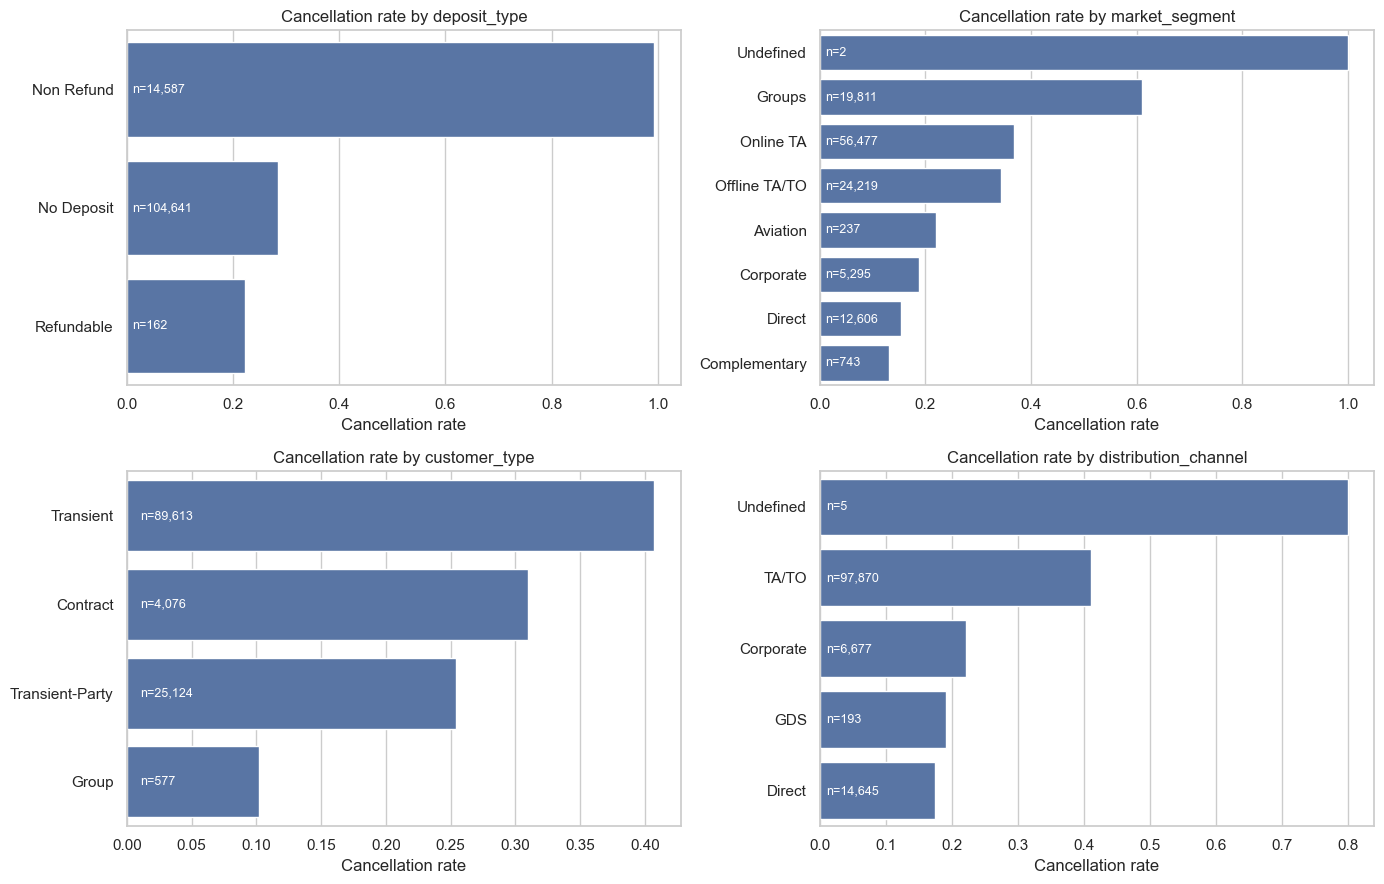

In [10]:
cat_cols_to_check = ["deposit_type", "market_segment", "customer_type", "distribution_channel"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.flat, cat_cols_to_check):
    rates = df.groupby(col)["is_canceled"].agg(["mean", "size"]).sort_values("mean", ascending=False)
    sns.barplot(x=rates["mean"], y=rates.index, ax=ax, orient="h")
    ax.set_title(f"Cancellation rate by {col}")
    ax.set_xlabel("Cancellation rate")
    ax.set_ylabel("")
    for i, n in enumerate(rates["size"]):
        ax.text(0.01, i, f"n={n:,}", va="center", color="white", fontsize=9)
plt.tight_layout()
plt.show()

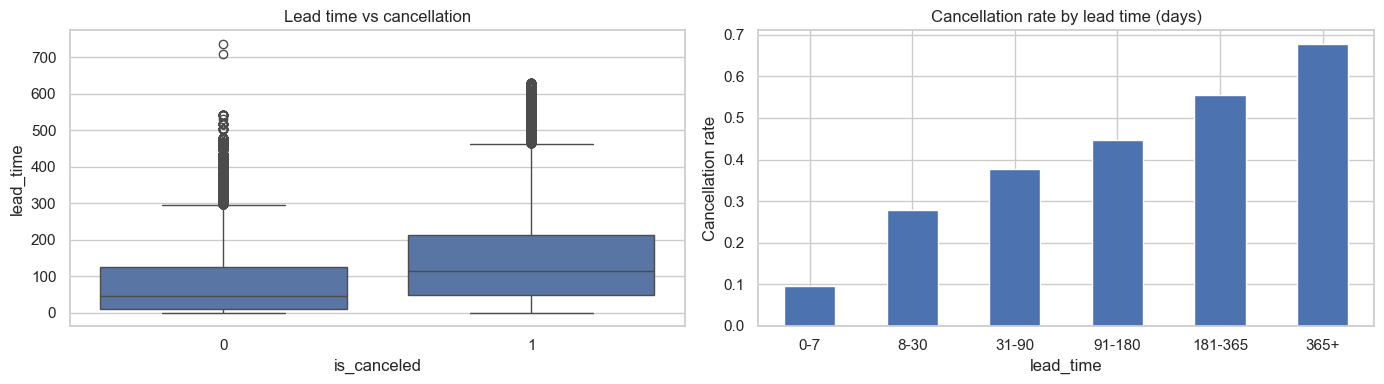

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.boxplot(data=df, x="is_canceled", y="lead_time", ax=axes[0])
axes[0].set_title("Lead time vs cancellation")

# cancellation rate by lead-time bucket
lead_bins = pd.cut(df["lead_time"], bins=[-1, 7, 30, 90, 180, 365, 800],
                   labels=["0-7", "8-30", "31-90", "91-180", "181-365", "365+"])
df.groupby(lead_bins, observed=True)["is_canceled"].mean().plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("Cancellation rate by lead time (days)")
axes[1].set_ylabel("Cancellation rate")
plt.tight_layout()
plt.show()

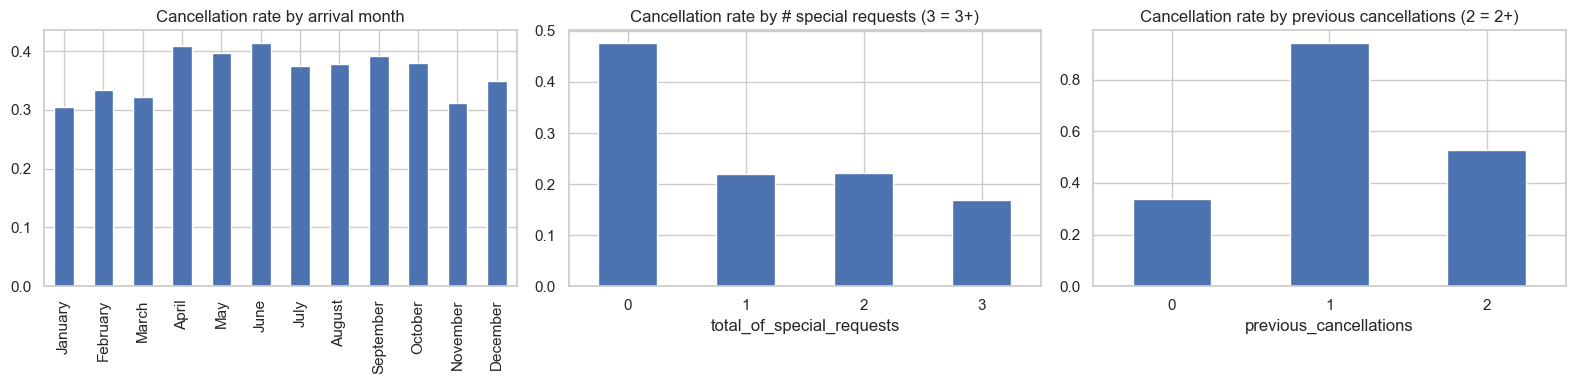

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

month_order = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]
df.groupby("arrival_date_month")["is_canceled"].mean().reindex(month_order).plot(
    kind="bar", ax=axes[0])
axes[0].set_title("Cancellation rate by arrival month")
axes[0].set_xlabel("")

df.groupby(df["total_of_special_requests"].clip(upper=3))["is_canceled"].mean().plot(
    kind="bar", ax=axes[1], rot=0)
axes[1].set_title("Cancellation rate by # special requests (3 = 3+)")

df.groupby(df["previous_cancellations"].clip(upper=2))["is_canceled"].mean().plot(
    kind="bar", ax=axes[2], rot=0)
axes[2].set_title("Cancellation rate by previous cancellations (2 = 2+)")
plt.tight_layout()
plt.show()

### EDA takeaways

1. **`deposit_type` is a very strong signal, but a strange one.** *Non Refund* bookings cancel ~99% of the time, even though you'd expect people who can't get their money back to show up. This is a known quirk of this dataset. These are mostly large group/tour-operator blocks (look at the `Groups` market segment) that are booked as placeholders and released in bulk. It's real information known at booking time, so we keep it, but it's the kind of thing to **flag to a client**.
2. **Lead time matters a lot.** Bookings made within a week of arrival cancel ~10% of the time. Bookings made more than a year ahead cancel ~68% of the time. Plans change.
3. **Special requests lower cancellation risk.** Guests with zero requests cancel ~48% of the time, compared with ~22% for guests with one or more. People who ask for things (a crib, a high floor, …) are committed to coming.
4. **Guest history matters.** Guests with exactly one previous cancellation cancel again ~94% of the time.
5. **Channel matters.** `Groups` (~61%) and travel agents (`Online TA` / `Offline TA/TO`, ~35%) cancel the most. `Direct` (~15%) and `Corporate` (~19%) cancel the least. `Transient` customers (~41%) cancel more than any other customer type.
6. **Season matters less.** Monthly rates only range from ~31% to ~42%.
7. Classes are moderately imbalanced (37/63), so we'll stratify our split and look beyond accuracy.

# STEP 4: DATA CLEANING / PREPROCESSING

We clean a **copy** so the raw `df` stays untouched:

1. Duplicates
2. Data types
3. Extreme / impossible values
4. Missing values
5. Inconsistent labels

### 1. Duplicates

This dataset has **no booking ID**, so an exact duplicate row could be either:
- a genuinely separate booking (e.g. a tour operator reserving 20 identical rooms), or
- the same booking recorded more than once.

Either way, identical rows hurt evaluation. If the same row lands in both train and test, the model is "tested" on rows it has already memorised, and its score looks better than it would on new bookings. We **drop duplicates** and accept that we lose a bit of real volume.

In [13]:
cleaned_df = df.copy()
print("Original shape:", cleaned_df.shape)
print("Duplicate rows:", cleaned_df.duplicated().sum())
print("Cancellation rate BEFORE dropping duplicates:", round(cleaned_df["is_canceled"].mean(), 3))

cleaned_df = cleaned_df.drop_duplicates()
print("\nShape after dropping duplicates:", cleaned_df.shape)
print("Cancellation rate AFTER dropping duplicates:", round(cleaned_df["is_canceled"].mean(), 3))

Original shape: (119390, 32)
Duplicate rows: 31994
Cancellation rate BEFORE dropping duplicates: 0.37

Shape after dropping duplicates: (87396, 32)
Cancellation rate AFTER dropping duplicates: 0.275


In [14]:
# where did the duplicates come from?
dupe_mask = df.duplicated(keep=False)
pd.DataFrame({
    "rows_in_raw_data": df["deposit_type"].value_counts(),
    "rows_after_dedup": cleaned_df["deposit_type"].value_counts()
})

,rows_in_raw_data,rows_after_dedup
deposit_type,,
No Deposit,104641,86251
Non Refund,14587,1038
Refundable,162,107


**This changes the story.** Most of the duplicates were **Non Refund** bookings, the bulk group blocks we flagged in EDA (14,587 rows → about 1,000). After deduplication:
- the cancellation rate drops from ~37% to **~27.5%**, so the "always predict not cancelled" baseline is now **~72.5% accuracy**. That's an even stronger reason not to judge models on accuracy alone.
- the "Non Refund = 99% cancel" signal is still there, but it applies to far fewer bookings.

Lesson: a cleaning decision can change your conclusions. Always check the before/after.

### 2. Data types

In [15]:
# children is stored as float only because of its 4 NaNs; fill those (0) and make it an integer
cleaned_df["children"] = cleaned_df["children"].fillna(0).astype(int)

# build a real arrival date from the year / month / day columns
cleaned_df["arrival_date"] = pd.to_datetime(
    cleaned_df["arrival_date_year"].astype(str) + "-"
    + cleaned_df["arrival_date_month"] + "-"
    + cleaned_df["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d"
)
cleaned_df[["arrival_date_year", "arrival_date_month", "arrival_date_day_of_month", "arrival_date"]].head()

,arrival_date_year,arrival_date_month,arrival_date_day_of_month,arrival_date
0,2015,July,1,2015-07-01
1,2015,July,1,2015-07-01
2,2015,July,1,2015-07-01
3,2015,July,1,2015-07-01
4,2015,July,1,2015-07-01


### 3. Extreme / impossible values

In [16]:
total_guests = cleaned_df["adults"] + cleaned_df["children"] + cleaned_df["babies"]

print("Rows with negative ADR (price):", (cleaned_df["adr"] < 0).sum())
print("Rows with ADR > 1000/night:", (cleaned_df["adr"] > 1000).sum())
print("Rows with zero guests:", (total_guests == 0).sum())

# a booking with no guests or a negative price is a data-entry error, and one 5,400/night booking is a typo-level outlier
cleaned_df = cleaned_df[(cleaned_df["adr"] >= 0) & (cleaned_df["adr"] <= 1000) & (total_guests > 0)]
print("\nShape after removing impossible values:", cleaned_df.shape)

Rows with negative ADR (price): 1
Rows with ADR > 1000/night: 1
Rows with zero guests: 166

Shape after removing impossible values: (87228, 33)


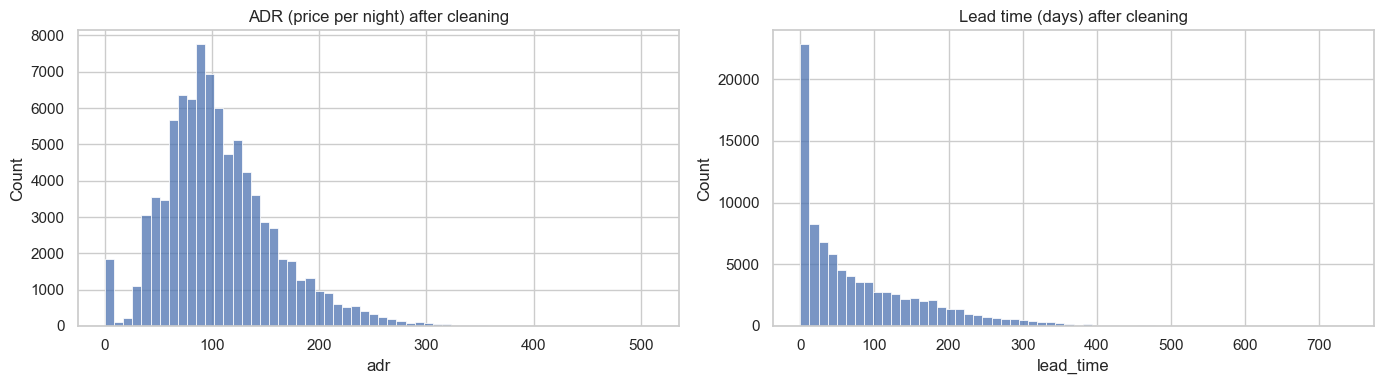

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(cleaned_df["adr"], bins=60, ax=axes[0])
axes[0].set_title("ADR (price per night) after cleaning")
sns.histplot(cleaned_df["lead_time"], bins=60, ax=axes[1])
axes[1].set_title("Lead time (days) after cleaning")
plt.tight_layout()
plt.show()

ADR of 0 is kept on purpose: those are mostly `Complementary` (free) stays, which are real. Lead time is right-skewed, but long lead times are genuine bookings and carry signal, so we keep them. Tree models don't mind skew, and we scale numbers for the linear model.

### 4. Missing values

In [18]:
print("Missing before handling:")
print(cleaned_df[["children", "country", "agent", "company"]].isnull().sum())

# agent / company: missing = 'no agent / no company involved'. That absence is information, so keep it as a flag.
cleaned_df["has_agent"] = cleaned_df["agent"].notnull().astype(int)
cleaned_df["has_company"] = cleaned_df["company"].notnull().astype(int)

# country: a small number missing, so fill with an explicit 'Unknown' category instead of dropping rows
cleaned_df["country"] = cleaned_df["country"].fillna("Unknown")

print("\nMissing after handling (agent/company IDs will be dropped in feature selection):")
print(cleaned_df[["children", "country", "has_agent", "has_company"]].isnull().sum())

Missing before handling:
children        0
country       447
agent       12141
company     81991
dtype: int64

Missing after handling (agent/company IDs will be dropped in feature selection):
children       0
country        0
has_agent      0
has_company    0
dtype: int64


### 5. Inconsistent labels

In [19]:
print(cleaned_df["meal"].value_counts())

# per the dataset documentation, 'Undefined' and 'SC' both mean 'no meal package', so merge them
cleaned_df["meal"] = cleaned_df["meal"].replace("Undefined", "SC")

# strip stray whitespace from all text columns
for col in cleaned_df.select_dtypes(include="object").columns:
    cleaned_df[col] = cleaned_df[col].str.strip()

print("\nAfter merging:")
print(cleaned_df["meal"].value_counts())
print("\nCleaned shape:", cleaned_df.shape)

meal
BB           67905
SC            9391
HB            9080
Undefined      492
FB             360
Name: count, dtype: int64



After merging:
meal
BB    67905
SC     9883
HB     9080
FB      360
Name: count, dtype: int64

Cleaned shape: (87228, 35)


### One more leakage check: parking spaces

In [20]:
cleaned_df.groupby(cleaned_df["required_car_parking_spaces"] > 0)["is_canceled"].agg(["mean", "size"])

,mean,size
required_car_parking_spaces,,
False,0.300393,79922
True,0.000000,7306


**Not one** booking with a parking space was cancelled, out of thousands. Real customer behaviour is never that clean. The likely explanation is that parking is recorded **when the guest arrives**, so only guests who showed up can have it. That makes it another **leaky** column (known only after the outcome), and we will **not** use it.

**How to spot leakage:** be suspicious of any feature that predicts the target *perfectly* or close to it. Ask "would I actually know this at prediction time?"

# STEP 5: FEATURE ENGINEERING

We turn raw columns into features that describe a booking the way a hotel manager would think about it.

In [21]:
model_df = cleaned_df.copy()

# stay and party size
model_df["total_nights"] = model_df["stays_in_weekend_nights"] + model_df["stays_in_week_nights"]
model_df["total_guests"] = model_df["adults"] + model_df["children"] + model_df["babies"]
model_df["is_family"] = ((model_df["children"] + model_df["babies"]) > 0).astype(int)
model_df["adr_per_person"] = model_df["adr"] / model_df["total_guests"]

# guest history: has this guest ever cancelled before?
model_df["has_prev_cancellation"] = (model_df["previous_cancellations"] > 0).astype(int)

# arrival timing
model_df["arrival_month_num"] = model_df["arrival_date"].dt.month
model_df["arrival_day_of_week"] = model_df["arrival_date"].dt.day_name()
model_df["arrival_is_weekend"] = (model_df["arrival_date"].dt.dayofweek >= 5).astype(int)

# cyclical encoding (same idea as the coffee notebook): December and January are neighbours
model_df["arrival_month_sin"] = np.sin(2 * np.pi * model_df["arrival_month_num"] / 12)
model_df["arrival_month_cos"] = np.cos(2 * np.pi * model_df["arrival_month_num"] / 12)

# country has ~170 values. One-hot encoding all of them would create ~170 mostly-empty columns.
# keep the 15 most common countries and group the rest as 'Other' (a standard high-cardinality fix)
top_countries = model_df["country"].value_counts().nlargest(15).index
model_df["country_grouped"] = model_df["country"].where(model_df["country"].isin(top_countries), "Other")

model_df[["total_nights", "total_guests", "is_family", "adr_per_person", "has_prev_cancellation",
          "arrival_month_num", "arrival_day_of_week", "arrival_month_sin", "country_grouped"]].head()

,total_nights,total_guests,is_family,adr_per_person,has_prev_cancellation,arrival_month_num,arrival_day_of_week,arrival_month_sin,country_grouped
0,0,2,0,0.0,0,7,Wednesday,-0.5,PRT
1,0,2,0,0.0,0,7,Wednesday,-0.5,PRT
2,1,1,0,75.0,0,7,Wednesday,-0.5,GBR
3,1,1,0,75.0,0,7,Wednesday,-0.5,GBR
4,2,2,0,49.0,0,7,Wednesday,-0.5,GBR


Let's check that the new features actually relate to cancellation:

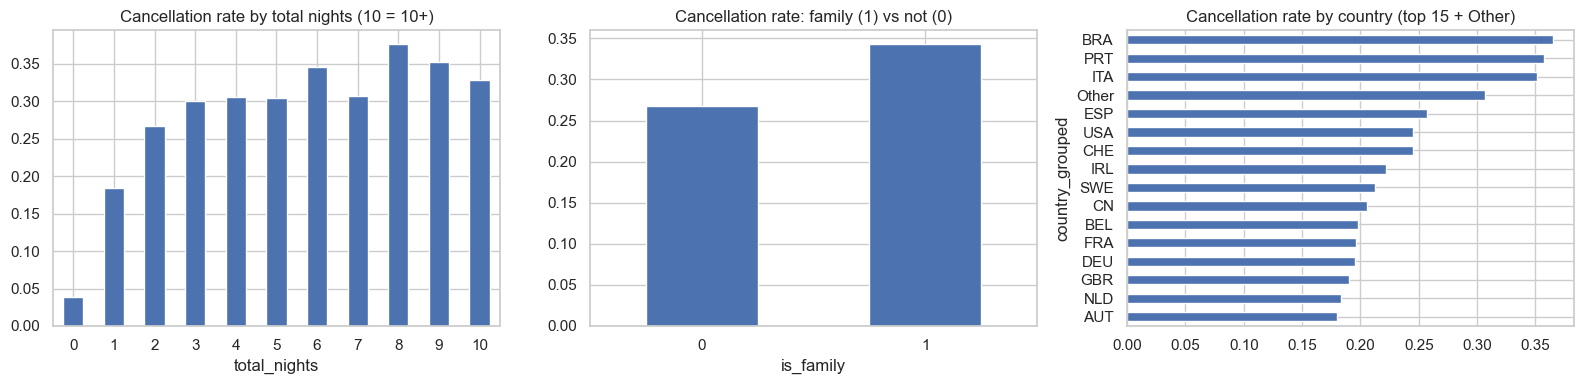

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

model_df.groupby(model_df["total_nights"].clip(upper=10))["is_canceled"].mean().plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Cancellation rate by total nights (10 = 10+)")

model_df.groupby("is_family")["is_canceled"].mean().plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("Cancellation rate: family (1) vs not (0)")

(model_df.groupby("country_grouped")["is_canceled"].mean().sort_values()
    .plot(kind="barh", ax=axes[2]))
axes[2].set_title("Cancellation rate by country (top 15 + Other)")
plt.tight_layout()
plt.show()

# STEP 5.5: FEATURE SELECTION

We choose the model's inputs. We **exclude**:

| Excluded column | Why |
|---|---|
| `reservation_status`, `reservation_status_date` | Target leakage: these *are* the outcome |
| `assigned_room_type`, `booking_changes`, `required_car_parking_spaces` | Only known after the booking plays out (future leakage) |
| `agent`, `company` (raw IDs) | Hundreds of ID values; replaced by `has_agent` / `has_company` |
| `country` (raw) | Replaced by `country_grouped` |
| `arrival_date_year` | Year doesn't generalise. A future booking will be in a year the model has never seen |
| `arrival_date`, `arrival_date_month` | Replaced by the engineered month features |

In [23]:
target_col = "is_canceled"

numeric_features = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "total_nights",
    "adults",
    "children",
    "babies",
    "total_guests",
    "is_family",
    "adr",
    "adr_per_person",
    "is_repeated_guest",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "has_prev_cancellation",
    "days_in_waiting_list",
    "total_of_special_requests",
    "has_agent",
    "has_company",
    "arrival_date_week_number",
    "arrival_date_day_of_month",
    "arrival_is_weekend",
    "arrival_month_sin",
    "arrival_month_cos",
]

categorical_features = [
    "hotel",
    "meal",
    "country_grouped",
    "market_segment",
    "distribution_channel",
    "reserved_room_type",
    "deposit_type",
    "customer_type",
    "arrival_day_of_week",
]

features = numeric_features + categorical_features

X = model_df[features]
y = model_df[target_col]

print("Number of features:", len(features))
print("X shape:", X.shape)
print("y shape:", y.shape)
X.head()

Number of features: 33
X shape: (87228, 33)
y shape: (87228,)


,lead_time,stays_in_weekend_nights,stays_in_week_nights,total_nights,adults,children,babies,total_guests,is_family,adr,adr_per_person,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,has_prev_cancellation,days_in_waiting_list,total_of_special_requests,has_agent,has_company,arrival_date_week_number,arrival_date_day_of_month,arrival_is_weekend,arrival_month_sin,arrival_month_cos,hotel,meal,country_grouped,market_segment,distribution_channel,reserved_room_type,deposit_type,customer_type,arrival_day_of_week
0,342,0,0,0,2,0,0,2,0,0.0,0.0,0,0,0,0,0,0,0,0,27,1,0,-0.5,-0.866025,Resort Hotel,BB,PRT,Direct,Direct,C,No Deposit,Transient,Wednesday
1,737,0,0,0,2,0,0,2,0,0.0,0.0,0,0,0,0,0,0,0,0,27,1,0,-0.5,-0.866025,Resort Hotel,BB,PRT,Direct,Direct,C,No Deposit,Transient,Wednesday
2,7,0,1,1,1,0,0,1,0,75.0,75.0,0,0,0,0,0,0,0,0,27,1,0,-0.5,-0.866025,Resort Hotel,BB,GBR,Direct,Direct,A,No Deposit,Transient,Wednesday
3,13,0,1,1,1,0,0,1,0,75.0,75.0,0,0,0,0,0,0,1,0,27,1,0,-0.5,-0.866025,Resort Hotel,BB,GBR,Corporate,Corporate,A,No Deposit,Transient,Wednesday
4,14,0,2,2,2,0,0,2,0,98.0,49.0,0,0,0,0,0,1,1,0,27,1,0,-0.5,-0.866025,Resort Hotel,BB,GBR,Online TA,TA/TO,A,No Deposit,Transient,Wednesday


# STEP 6: TRAIN / TEST SPLIT

80/20 split, **stratified** on `is_canceled`, so both sets keep the same ~27.5% cancellation rate.

**Rule for the rest of the notebook:** the test set is locked away. We compare and tune models using **cross-validation on the training set only**, and touch the test set **once**, at the very end, to report the final score. (The coffee notebook chose its best model by test accuracy. That quietly turns the test set into part of training, and the final score ends up optimistic.)

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("\nTrain cancellation rate:", round(y_train.mean(), 3))
print("Test cancellation rate: ", round(y_test.mean(), 3))

Training rows: 69782
Testing rows: 17446

Train cancellation rate: 0.275
Test cancellation rate:  0.275


# STEP 7: MODEL SELECTION

1. Preprocessing pipeline
2. Baseline model
3. Compare models with cross-validation

## Preprocessing Pipeline

- **Numeric features:** fill any gaps with the median, then scale (`StandardScaler`). Scaling matters for Logistic Regression and doesn't hurt tree models.
- **Categorical features:** fill gaps with the most frequent value, then **one-hot encode**, with `handle_unknown="ignore"` so a category that only appears in new data doesn't crash the model.

Because all of this lives inside a `Pipeline`, it is **fit on training data only**, including inside every cross-validation fold. That prevents the test data from leaking in through things like the median or the scaler's mean.

In [25]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

preprocessor

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


## Baseline Model

"How well can we do with no real model?" The `DummyClassifier` always predicts the most common class (*not cancelled*). We score it with 5-fold cross-validation on the training data.

In [26]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

baseline_model = DummyClassifier(strategy="most_frequent")
baseline_acc = cross_val_score(baseline_model, X_train, y_train, cv=cv, scoring="accuracy").mean()
baseline_auc = cross_val_score(baseline_model, X_train, y_train, cv=cv, scoring="roc_auc").mean()

print("Baseline CV accuracy:", round(baseline_acc, 3))
print("Baseline CV ROC-AUC: ", round(baseline_auc, 3))

Baseline CV accuracy: 0.725
Baseline CV ROC-AUC:  0.5


The baseline gets ~72.5% accuracy **without catching a single cancellation**, and its ROC-AUC is 0.5 (no better than a coin flip at ranking). Any useful model has to beat **0.5 ROC-AUC** by a wide margin.

## Model Selection and Training

We compare six models. Each one uses the same preprocessing pipeline and the same 5 cross-validation folds on the **training set**, so the comparison is fair.

**What about class imbalance?** The coffee notebook used `class_weight="balanced"`. Here we leave it off. Our minority class is 27.5%, which is only moderate. We judge models with ROC-AUC, which isn't affected by imbalance. And in Step 8 we'll pick a **decision threshold** that fits the hotel's business needs. Adjusting the threshold is a more flexible way to trade off catching cancellations against false alarms.

In [27]:
from sklearn.model_selection import cross_validate

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=10, min_samples_leaf=20, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
    "Extra Trees": ExtraTreesClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

cv_results = []
for name, model in models.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv,
                            scoring=["roc_auc", "accuracy", "f1"], n_jobs=-1)
    cv_results.append({
        "model": name,
        "mean_cv_roc_auc": scores["test_roc_auc"].mean(),
        "std_cv_roc_auc": scores["test_roc_auc"].std(),
        "mean_cv_accuracy": scores["test_accuracy"].mean(),
        "mean_cv_f1": scores["test_f1"].mean(),
        "fit_time_sec": scores["fit_time"].mean(),
    })

cv_results_df = pd.DataFrame(cv_results).sort_values("mean_cv_roc_auc", ascending=False).round(4)
cv_results_df

,model,mean_cv_roc_auc,std_cv_roc_auc,mean_cv_accuracy,mean_cv_f1,fit_time_sec
2,Random Forest,0.8763,0.0039,0.8248,0.6343,8.1336
5,Hist Gradient Boosting,0.8693,0.0042,0.8156,0.6238,3.4167
3,Extra Trees,0.8651,0.0050,0.8156,0.5933,9.3968
4,Gradient Boosting,0.8490,0.0048,0.8033,0.5791,14.9445
1,Decision Tree,0.8371,0.0038,0.8005,0.5959,0.4293
0,Logistic Regression,0.8065,0.0056,0.7817,0.5071,0.4395


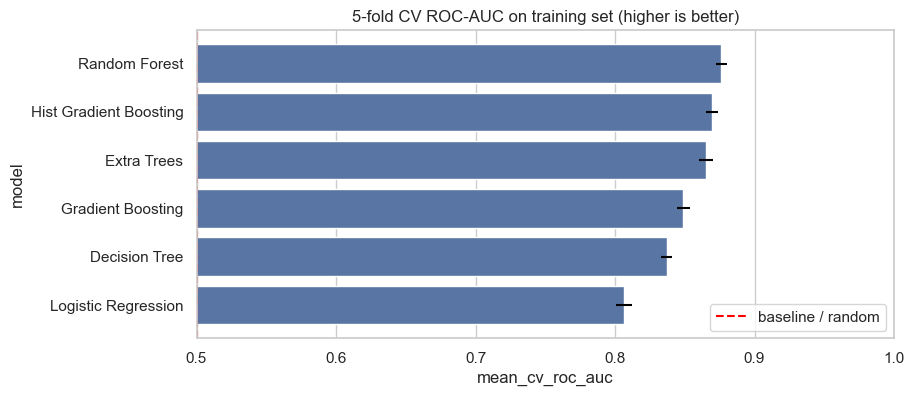

Best model by CV ROC-AUC: Random Forest


In [28]:
plt.figure(figsize=(9, 4))
sns.barplot(data=cv_results_df, x="mean_cv_roc_auc", y="model", orient="h")
plt.errorbar(cv_results_df["mean_cv_roc_auc"], range(len(cv_results_df)),
             xerr=cv_results_df["std_cv_roc_auc"], fmt="none", color="black")
plt.xlim(0.5, 1.0)
plt.axvline(0.5, color="red", linestyle="--", label="baseline / random")
plt.title("5-fold CV ROC-AUC on training set (higher is better)")
plt.legend()
plt.show()

best_model_name = cv_results_df.iloc[0]["model"]
print("Best model by CV ROC-AUC:", best_model_name)

### Why compare multiple models?

There is no single best model for every dataset:
- **Logistic Regression** learns roughly linear relationships. It's simple and interpretable, a strong "sanity check" model.
- **Decision Tree** learns if/then rules. It's interpretable but tends to overfit.
- **Random Forest** averages many trees trained on random subsets, which reduces overfitting.
- **Extra Trees** is like a random forest with even more randomness in the splits.
- **Gradient Boosting / Hist Gradient Boosting** build trees one after another, each fixing the previous one's mistakes. They're often the strongest on tabular data. The "Hist" version bins the numbers first, which makes it much faster on large datasets like this one.

The small standard deviations across folds tell us the ranking is **stable**, not luck from one split.

# STEP 7.5: HYPERPARAMETER TUNING

- **Parameters** are learned from the data (e.g. the split points inside each tree).
- **Hyperparameters** are settings *we* choose before training (number of trees, tree depth, learning rate, …).

`GridSearchCV` tries every combination in a grid and scores each one with cross-validation **on the training set**.

Random Forest and Hist Gradient Boosting finished close together (0.876 vs 0.869), and tuning could flip the order. So we tune **both** and keep whichever has the higher tuned CV score. (The coffee notebook tuned Random Forest even though a different model had won. Always tune your actual front-runners.)

In [29]:
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(n_estimators=300, n_jobs=1, random_state=RANDOM_STATE))
])

rf_param_grid = {
    "model__max_depth": [None, 20, 30],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.3],
}

rf_search = GridSearchCV(rf_pipeline, param_grid=rf_param_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
rf_search.fit(X_train, y_train)

print("Random Forest: best params:", rf_search.best_params_)
print("Random Forest: best CV ROC-AUC:", round(rf_search.best_score_, 4))

/opt/anaconda3/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Random Forest: best params: {'model__max_depth': None, 'model__max_features': 0.3, 'model__min_samples_leaf': 2}
Random Forest: best CV ROC-AUC: 0.8773


In [30]:
hgb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", HistGradientBoostingClassifier(random_state=RANDOM_STATE))
])

hgb_param_grid = {
    "model__learning_rate": [0.05, 0.1],
    "model__max_iter": [300, 600],
    "model__max_leaf_nodes": [31, 63, 127],
    "model__min_samples_leaf": [20, 50],
}

hgb_search = GridSearchCV(hgb_pipeline, param_grid=hgb_param_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
hgb_search.fit(X_train, y_train)

print("Hist Gradient Boosting: best params:", hgb_search.best_params_)
print("Hist Gradient Boosting: best CV ROC-AUC:", round(hgb_search.best_score_, 4))

Hist Gradient Boosting: best params: {'model__learning_rate': 0.05, 'model__max_iter': 600, 'model__max_leaf_nodes': 127, 'model__min_samples_leaf': 20}
Hist Gradient Boosting: best CV ROC-AUC: 0.8785


In [31]:
tuning_summary = pd.DataFrame({
    "model": ["Random Forest", "Hist Gradient Boosting"],
    "untuned_cv_roc_auc": [
        cv_results_df.set_index("model").loc["Random Forest", "mean_cv_roc_auc"],
        cv_results_df.set_index("model").loc["Hist Gradient Boosting", "mean_cv_roc_auc"],
    ],
    "tuned_cv_roc_auc": [rf_search.best_score_, hgb_search.best_score_],
}).round(4)
print(tuning_summary)

searches = {"Random Forest": rf_search, "Hist Gradient Boosting": hgb_search}
final_model_name = max(searches, key=lambda k: searches[k].best_score_)
final_model = searches[final_model_name].best_estimator_  # GridSearchCV refits the best settings on ALL training data
print("\nFinal model:", final_model_name)

                    model  untuned_cv_roc_auc  tuned_cv_roc_auc
0           Random Forest              0.8763            0.8773
1  Hist Gradient Boosting              0.8693            0.8785

Final model: Hist Gradient Boosting


### Choosing a decision threshold

By default a classifier predicts "cancel" when its probability is above **0.5**. For a business, 0.5 isn't sacred. The right cut-off depends on what each kind of mistake costs:
- **False positive** (we flag a booking that would have shown up): e.g. we ask a loyal guest for a deposit. Mildly annoying.
- **False negative** (we miss a real cancellation): the room may sit empty. Lost revenue.

We pick the threshold that maximises **F1** (a balance of precision and recall) using **out-of-fold predictions on the training set**. Each training row gets a prediction from a model that didn't see it. This keeps the test set untouched.

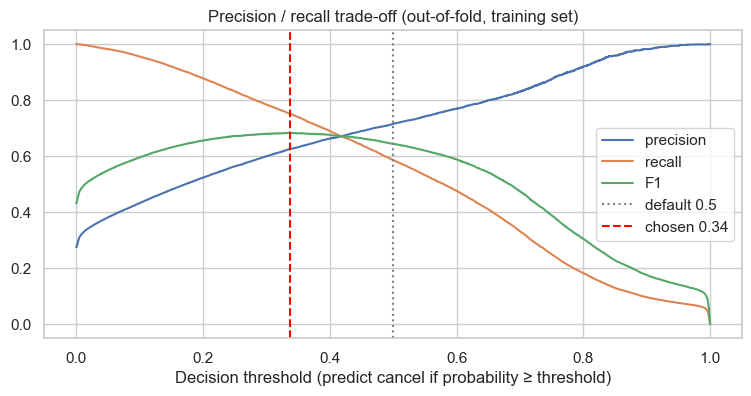

Chosen threshold: 0.337


In [32]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

oof_proba = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_train, oof_proba)
f1s = 2 * precisions[:-1] * recalls[:-1] / (precisions[:-1] + recalls[:-1] + 1e-12)
best_threshold = thresholds[np.argmax(f1s)]

plt.figure(figsize=(9, 4))
plt.plot(thresholds, precisions[:-1], label="precision")
plt.plot(thresholds, recalls[:-1], label="recall")
plt.plot(thresholds, f1s, label="F1")
plt.axvline(0.5, color="gray", linestyle=":", label="default 0.5")
plt.axvline(best_threshold, color="red", linestyle="--", label=f"chosen {best_threshold:.2f}")
plt.xlabel("Decision threshold (predict cancel if probability ≥ threshold)")
plt.title("Precision / recall trade-off (out-of-fold, training set)")
plt.legend()
plt.show()

print("Chosen threshold:", round(best_threshold, 3))

# STEP 8: FINAL EVALUATION ON THE TEST SET

This is the **first and only time** we use the test set. The scores below estimate how the model will do on bookings it has never seen.

In [33]:
from sklearn.metrics import roc_curve

test_proba = final_model.predict_proba(X_test)[:, 1]
test_preds_default = (test_proba >= 0.5).astype(int)
final_preds = (test_proba >= best_threshold).astype(int)

def summarize(name, preds):
    return {
        "setting": name,
        "accuracy": accuracy_score(y_test, preds),
        "precision (cancel)": precision_score(y_test, preds),
        "recall (cancel)": recall_score(y_test, preds),
        "f1 (cancel)": f1_score(y_test, preds),
    }

test_auc = roc_auc_score(y_test, test_proba)
print(f"Test ROC-AUC: {test_auc:.4f}   (CV estimate was {searches[final_model_name].best_score_:.4f})")

results_df = pd.DataFrame([
    summarize("Baseline (always 'not cancelled')", np.zeros_like(y_test)),
    summarize("Final model @ 0.50", test_preds_default),
    summarize(f"Final model @ {best_threshold:.2f}", final_preds),
]).round(3)
results_df

Test ROC-AUC: 0.8853   (CV estimate was 0.8785)


/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,setting,accuracy,precision (cancel),recall (cancel),f1 (cancel)
0,Baseline (always 'not cancelled'),0.725,0.000,0.000,0.000
1,Final model @ 0.50,0.826,0.721,0.599,0.655
2,Final model @ 0.34,0.811,0.630,0.763,0.690


The test ROC-AUC lands very close to the cross-validation estimate. That's what we want to see: our CV process was honest, and the model isn't overfit to the training data.

In [34]:
print(f"Classification report: {final_model_name} @ threshold {best_threshold:.2f}")
print(classification_report(y_test, final_preds, target_names=["kept (0)", "cancelled (1)"]))

Classification report: Hist Gradient Boosting @ threshold 0.34
               precision    recall  f1-score   support

     kept (0)       0.90      0.83      0.86     12644
cancelled (1)       0.63      0.76      0.69      4802

     accuracy                           0.81     17446
    macro avg       0.77      0.80      0.78     17446
 weighted avg       0.83      0.81      0.82     17446



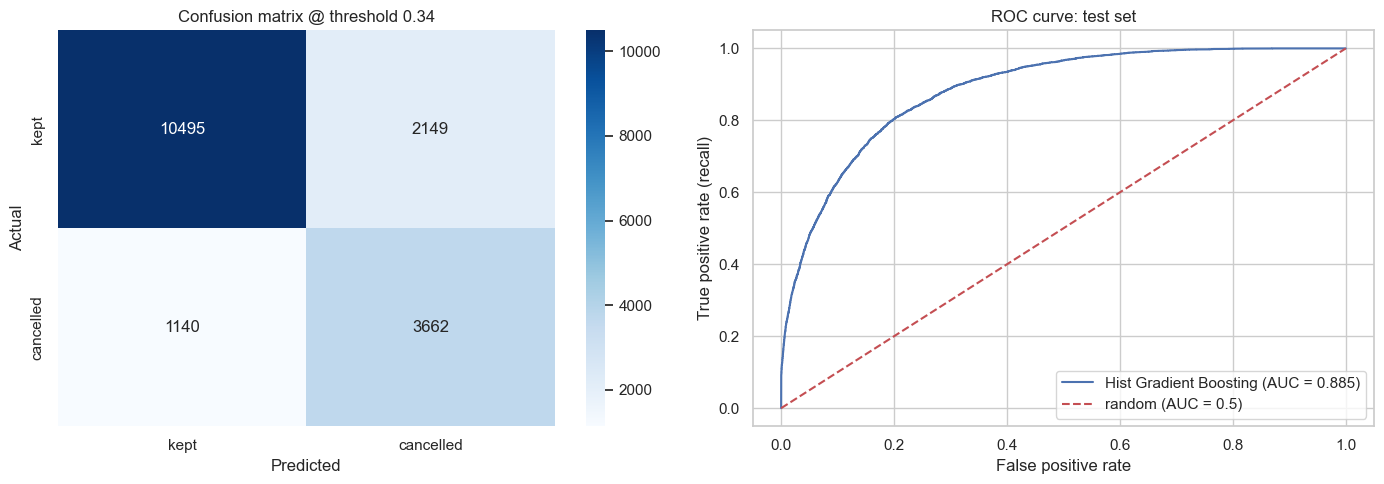

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, final_preds)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["kept", "cancelled"], yticklabels=["kept", "cancelled"])
axes[0].set_title(f"Confusion matrix @ threshold {best_threshold:.2f}")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

fpr, tpr, _ = roc_curve(y_test, test_proba)
axes[1].plot(fpr, tpr, label=f"{final_model_name} (AUC = {test_auc:.3f})")
axes[1].plot([0, 1], [0, 1], "r--", label="random (AUC = 0.5)")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate (recall)")
axes[1].set_title("ROC curve: test set")
axes[1].legend()
plt.tight_layout()
plt.show()

## Robustness check: does it work on *future* bookings?

A random split mixes bookings from all dates into both train and test. In real life the hotel would train on the past and predict the **future**, and customer behaviour can drift over time. So we retrain the same model on arrivals **before 2017** and test it on **2017 arrivals**.

In [36]:
from sklearn.base import clone

arrival_dates = model_df.loc[X.index, "arrival_date"]
past = arrival_dates < "2017-01-01"

temporal_model = clone(final_model)
temporal_model.fit(X[past], y[past])
temporal_auc = roc_auc_score(y[~past], temporal_model.predict_proba(X[~past])[:, 1])

print(f"Train on 2015-2016 ({past.sum():,} bookings) -> test on 2017 ({(~past).sum():,} bookings)")
print(f"Time-based ROC-AUC: {temporal_auc:.4f}   vs random-split test ROC-AUC: {test_auc:.4f}")

Train on 2015-2016 (55,596 bookings) -> test on 2017 (31,632 bookings)
Time-based ROC-AUC: 0.7745   vs random-split test ROC-AUC: 0.8853


# STEP 9: MODEL INTERPRETATION

Which features drive the predictions? We use **permutation importance**: shuffle one feature's values on the test set and measure how much ROC-AUC drops. A big drop means the model relies heavily on that feature.

Why not the built-in `feature_importances_` the coffee notebook used? Tree "impurity" importances are biased toward numeric features with many distinct values (like `lead_time` or `adr`). They also split each one-hot column apart, so you can't see the importance of "country" as a whole. Permutation importance works on the original columns and measures the actual effect on the metric.

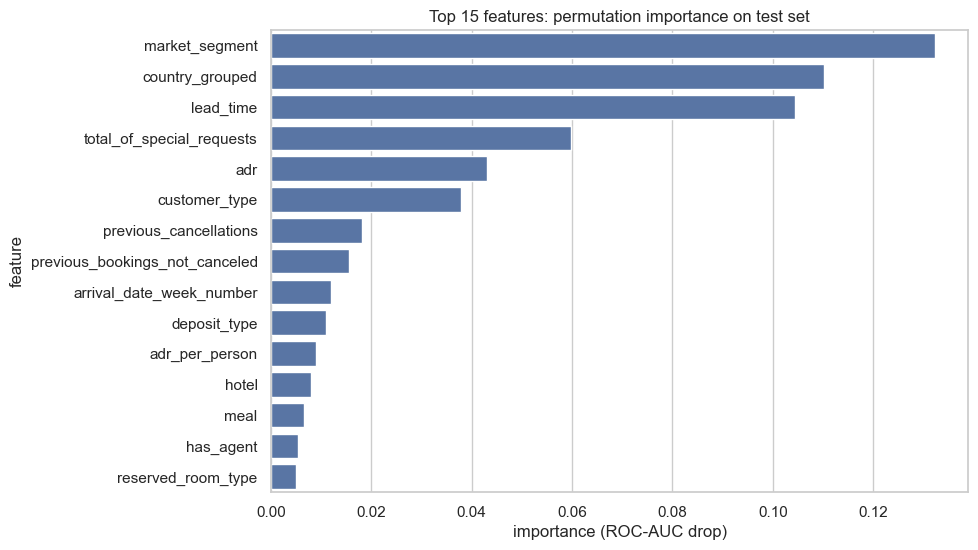

,feature,importance (ROC-AUC drop),std
0,market_segment,0.1324,0.0063
1,country_grouped,0.1103,0.0036
2,lead_time,0.1044,0.0079
3,total_of_special_requests,0.0598,0.0031
4,adr,0.0430,0.0021
5,customer_type,0.0378,0.0024
6,previous_cancellations,0.0181,0.0008
7,previous_bookings_not_canceled,0.0155,0.0025
8,arrival_date_week_number,0.0119,0.0010
9,deposit_type,0.0110,0.0004


In [37]:
from sklearn.inspection import permutation_importance

# use a 5,000-row sample of the test set to keep this fast
sample_idx = X_test.sample(5000, random_state=RANDOM_STATE).index
perm = permutation_importance(final_model, X_test.loc[sample_idx], y_test.loc[sample_idx],
                              scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)

importance_df = pd.DataFrame({
    "feature": features,
    "importance (ROC-AUC drop)": perm.importances_mean,
    "std": perm.importances_std,
}).sort_values("importance (ROC-AUC drop)", ascending=False).reset_index(drop=True)

plt.figure(figsize=(9, 6))
top = importance_df.head(15)
sns.barplot(data=top, x="importance (ROC-AUC drop)", y="feature", orient="h")
plt.title("Top 15 features: permutation importance on test set")
plt.show()

importance_df.head(15).round(4)

To see *which direction* each top feature pushes risk, we compare the model's average predicted cancellation probability across feature values:

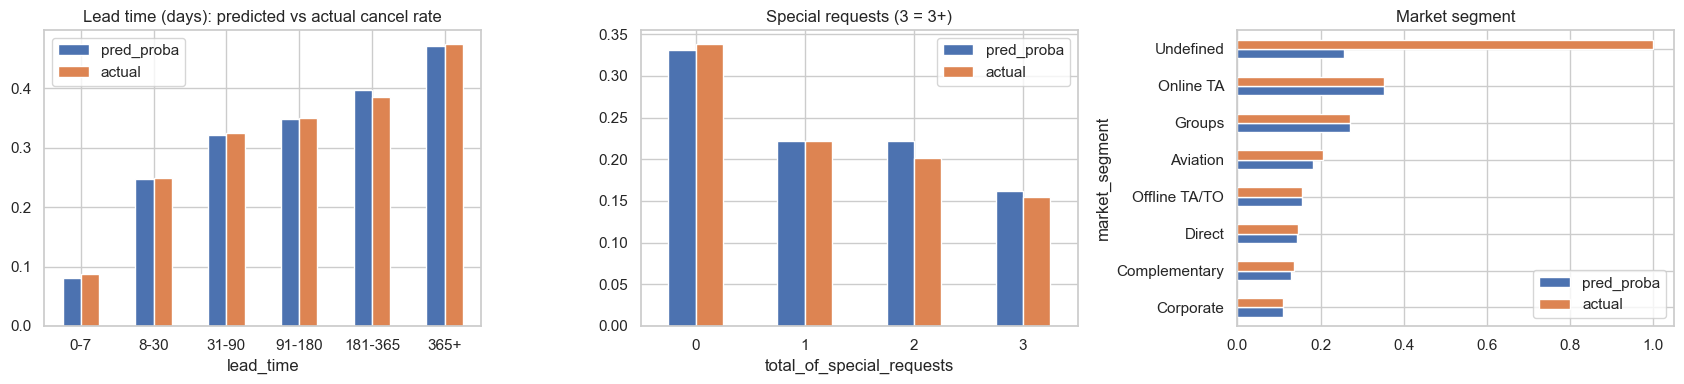

In [38]:
test_view = X_test.copy()
test_view["pred_proba"] = test_proba
test_view["actual"] = y_test.values

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
lead_bucket = pd.cut(test_view["lead_time"], bins=[-1, 7, 30, 90, 180, 365, 800],
                     labels=["0-7", "8-30", "31-90", "91-180", "181-365", "365+"])
test_view.groupby(lead_bucket, observed=True)[["pred_proba", "actual"]].mean().plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Lead time (days): predicted vs actual cancel rate")

test_view.groupby(test_view["total_of_special_requests"].clip(upper=3))[["pred_proba", "actual"]].mean().plot(
    kind="bar", ax=axes[1], rot=0)
axes[1].set_title("Special requests (3 = 3+)")

test_view.groupby("market_segment")[["pred_proba", "actual"]].mean().sort_values("actual").plot(
    kind="barh", ax=axes[2])
axes[2].set_title("Market segment")
plt.tight_layout()
plt.show()

# STEP 10: ERROR ANALYSIS

Where is the model going wrong? We split the errors into:
- **False positives:** predicted cancel, but the guest showed up
- **False negatives:** predicted kept, but the booking cancelled

In [39]:
errors = X_test.copy()
errors["actual"] = y_test.values
errors["predicted"] = final_preds
errors["pred_proba"] = test_proba
errors["error_type"] = np.select(
    [(errors["actual"] == 0) & (errors["predicted"] == 1),
     (errors["actual"] == 1) & (errors["predicted"] == 0)],
    ["false positive", "false negative"], default="correct")

print(errors["error_type"].value_counts())

error_type
correct           14157
false positive     2149
false negative     1140
Name: count, dtype: int64


In [40]:
# error rate by segment: where is the model weakest?
def error_table(col):
    g = errors.groupby(col)
    return pd.DataFrame({
        "bookings": g.size(),
        "actual_cancel_rate": g["actual"].mean(),
        "error_rate": g["error_type"].apply(lambda s: (s != "correct").mean()),
        "false_neg_rate": g["error_type"].apply(lambda s: (s == "false negative").mean()),
    }).sort_values("error_rate", ascending=False).round(3)

print("By market segment:")
print(error_table("market_segment"))
print("\nBy hotel:")
print(error_table("hotel"))

By market segment:
                bookings  actual_cancel_rate  error_rate  false_neg_rate
market_segment                                                          
Undefined              1               1.000       1.000           1.000
Online TA          10334               0.353       0.239           0.072
Aviation              34               0.206       0.206           0.088
Direct              2366               0.146       0.146           0.094
Complementary        133               0.135       0.120           0.105
Offline TA/TO       2751               0.156       0.100           0.028
Corporate            845               0.109       0.098           0.069
Groups               982               0.272       0.088           0.026

By hotel:
              bookings  actual_cancel_rate  error_rate  false_neg_rate
hotel                                                                 
City Hotel       10549               0.302       0.205           0.072
Resort Hotel      6897     

In [41]:
# the most confident mistakes: bookings the model was very sure about but got wrong
cols_to_show = ["pred_proba", "actual", "lead_time", "deposit_type", "market_segment", "customer_type",
                "total_of_special_requests", "previous_cancellations", "adr", "country_grouped", "hotel"]

print("Confident false negatives (model said 'safe', booking cancelled):")
display(errors[errors["error_type"] == "false negative"].nsmallest(8, "pred_proba")[cols_to_show])

print("Confident false positives (model said 'will cancel', guest showed up):")
display(errors[errors["error_type"] == "false positive"].nlargest(8, "pred_proba")[cols_to_show])

Confident false negatives (model said 'safe', booking cancelled):


,pred_proba,actual,lead_time,deposit_type,market_segment,customer_type,total_of_special_requests,previous_cancellations,adr,country_grouped,hotel
70258,0.003472,1,22,No Deposit,Offline TA/TO,Transient,0,0,99.00,Other,City Hotel
108829,0.006559,1,25,No Deposit,Corporate,Transient,0,0,125.00,FRA,City Hotel
17473,0.006813,1,283,No Deposit,Groups,Transient-Party,0,0,75.86,GBR,Resort Hotel
58478,0.007655,1,28,No Deposit,Groups,Transient-Party,0,0,120.00,GBR,City Hotel
22022,0.008371,1,0,No Deposit,Corporate,Transient-Party,0,0,58.50,PRT,Resort Hotel
32349,0.008788,1,0,No Deposit,Corporate,Transient,0,0,35.00,PRT,Resort Hotel
9610,0.009325,1,4,No Deposit,Corporate,Transient,2,0,30.00,Other,Resort Hotel
9375,0.012305,1,5,No Deposit,Online TA,Transient,3,0,65.83,GBR,Resort Hotel


Confident false positives (model said 'will cancel', guest showed up):


,pred_proba,actual,lead_time,deposit_type,market_segment,customer_type,total_of_special_requests,previous_cancellations,adr,country_grouped,hotel
14182,0.994792,0,80,No Deposit,Direct,Transient,0,1,195.00,PRT,Resort Hotel
111294,0.950113,0,327,No Deposit,Online TA,Transient,0,0,126.00,FRA,City Hotel
37863,0.933397,0,272,No Deposit,Online TA,Transient,1,0,80.10,PRT,Resort Hotel
77921,0.933357,0,1,No Deposit,Offline TA/TO,Transient,1,1,105.00,PRT,City Hotel
34161,0.926312,0,195,No Deposit,Groups,Transient-Party,0,0,62.28,PRT,Resort Hotel
1802,0.925996,0,354,No Deposit,Offline TA/TO,Contract,0,0,68.88,PRT,Resort Hotel
115031,0.923306,0,351,No Deposit,Online TA,Transient,0,0,99.00,NLD,City Hotel
103790,0.918707,0,248,No Deposit,Online TA,Transient,0,0,80.75,FRA,City Hotel


# STEP 11: SAVE THE MODEL

Saving the **whole pipeline** (preprocessing + model) means anyone can load it and call `.predict_proba()` on raw booking data, with no need to repeat the cleaning-and-encoding steps by hand. We also save the threshold and feature list, because the model is only correct when used with them.

In [42]:
import joblib
from pathlib import Path

Path("models").mkdir(exist_ok=True)
joblib.dump({
    "pipeline": final_model,
    "threshold": float(best_threshold),
    "features": features,
    "model_name": final_model_name,
}, "models/hotel_cancellation_model.joblib")

# sanity check: reload and predict
loaded = joblib.load("models/hotel_cancellation_model.joblib")
reloaded_proba = loaded["pipeline"].predict_proba(X_test[loaded["features"]].head())[:, 1]
print("Reloaded model predictions:", reloaded_proba.round(3))
print("Matches original:", np.allclose(reloaded_proba, test_proba[:5]))

Reloaded model predictions: [0.385 0.068 0.244 0.027 0.008]
Matches original: True


# STEP 12: WHAT THIS MEANS FOR THE HOTEL

## The short version

We can predict cancellations reasonably well using only what the hotel knows when the booking comes in. On held-out bookings the model scored a ROC-AUC of 0.885. At the threshold we picked (0.34), it caught about three out of every four bookings that ended up cancelling. Roughly 63% of the bookings it flagged really did cancel. That's a big step up from the baseline, which gets 72.5% accuracy by predicting "not cancelled" every time and never catches anything.

The model is far from perfect, though. About one in five predictions is wrong, and it does noticeably worse on future bookings than the random split suggests (more on that below).

## What drives cancellations

The patterns the model learned line up with what we saw in EDA, which is reassuring:

- How the booking came in matters most. Online travel agency bookings cancel a lot, while direct and corporate bookings rarely do.
- Lead time is huge. A booking made a week out almost always shows up, and one made a year out is closer to a coin flip.
- Guests who make special requests (a crib, a quiet room, a high floor) are much more likely to come. They've already pictured the trip.
- Price and customer type matter too, as does whether the guest has cancelled with the hotel before.

## How the hotel could use it

1. **Smarter overbooking.** Instead of a flat overbooking rate, the hotel can add up the predicted probabilities for a given night to estimate how many rooms will actually be empty, and overbook by about that much.
2. **Targeted deposits or reconfirmation.** Asking every guest for a deposit hurts conversion. Asking only the riskiest bookings (long lead time, online agency, no special requests) protects revenue without annoying most customers.
3. **Reach out before people cancel.** A reminder email or small perk sent a few weeks before arrival to high-risk bookings is cheap, and it might keep some of them.

The 0.34 threshold is a starting point, not a final answer. If the hotel tells us what a missed cancellation costs compared with an unnecessary deposit request, we can pick a threshold based on actual dollars.

## Things I'd flag to the client

- **It gets worse on future bookings.** When we trained on 2015–2016 and tested on 2017, ROC-AUC dropped from 0.885 to 0.775. Customer behaviour shifts over time, and a random split hides that. In practice the model would need to be retrained regularly on recent data, and the 0.775 is probably the more honest number to quote.
- **`country` might be leaking.** It's the second most important feature, but for some guests the country is likely only confirmed at check-in. If so, the model is partly using information from the future. Before anyone relies on this, it's worth asking the hotel how that field gets filled in, and testing the model without it.
- **The "Non Refund" bookings are weird.** In this data, non-refundable bookings cancel almost every time, which is the opposite of what you'd expect. They look like bulk group blocks rather than normal guests. That pattern may not hold at a different hotel.
- **We dropped about 32,000 duplicate rows.** Since there's no booking ID, some of those were probably real separate bookings (like a group reserving many identical rooms). Dropping them gives a more honest evaluation, but the model has seen fewer group bookings as a result.

## If we kept going

- Retrain on a rolling window of recent bookings and keep measuring on the latest months.
- Re-run without `country` (and double-check other fields with the hotel) to get a leak-free score.
- Bring in data the hotel likely has but this dataset doesn't, like price changes after booking, competitor prices, local events, and how many times a guest looked at the booking.
- Check whether the predicted probabilities are well calibrated, since overbooking math depends on "30% likely" really meaning 30%.